# 07 - Statistical Analysis: Logistic Regression on Simulated + Real Data

This notebook runs **logistic regression** to identify which interest-based features
predict hub formation, using both simulated and real YouTube data.

### Methodology

**Part A: Simulated Data**
- Generate synthetic node-level data that mimics interest-based network simulations.
- Fit a logistic regression with features: interest mean, Gini coefficient, kurtosis,
  entropy, distance/cosine to network centre, polarisation, concentration metrics.
- Evaluate with AUC-ROC and statsmodels summary (p-values, confidence intervals).

**Part B: Real YouTube Data**
- Load real channel feature data with a binary `core_nodes` target.
- Fit a logistic regression with interest and channel-level features.
- Compare coefficients and significance between simulated and real models.

**Part C: Comparison**
- Overlay feature distributions from real vs simulated data.
- Check whether the simulation reproduces the empirical patterns.

In [13]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.analysis.statistical_analysis import (
    generate_simulation_data,
    analyze_hub_formation,
    run_youtube_regression,
)
from src.visualization.comparison_plots import (
    plot_real_vs_simulation,
    plot_hub_characteristic_comparison,
)
from src.utils.config import get_data_path

## Configuration

| Parameter | Description | Value |
|-----------|-------------|-------|
| `n_nodes` | Nodes per simulation | 100 |
| `n_simulations` | Number of simulated networks | 20 |
| `youtube_data_path` | Path to real channel features CSV | `data/processed/channel_features.csv` |

In [14]:
N_NODES = 100
N_SIMULATIONS = 20
YOUTUBE_DATA_PATH = str(get_data_path('processed') / 'channel_features.csv')

print(f"Simulation: {N_SIMULATIONS} networks x {N_NODES} nodes = {N_SIMULATIONS * N_NODES} observations")
print(f"YouTube data path: {YOUTUBE_DATA_PATH}")

Simulation: 20 networks x 100 nodes = 2000 observations
YouTube data path: /Users/shalemsuma/Desktop/College/Capstone/interest-heterogeneity-network-formation/data/processed/channel_features.csv


---
## Part A: Simulated Data Analysis

### Generate Synthetic Data

The `generate_simulation_data` function creates node-level observations with realistic
correlations between interest features and hub status. The data-generating process
uses a latent variable model:

$$P(\text{hub} = 1) = \sigma(-1.8 \cdot \text{interest\_mean} - 1.4 \cdot \text{interest\_gini} + 2.2 \cdot \text{distance} + 1.9 \cdot \text{cosine} + \ldots)$$

This encodes the theoretical prediction: nodes with **lower** interest concentration
(low mean, low Gini) but **higher** network centrality (high distance, cosine)
are more likely to become hubs.

In [15]:
node_df, network_df = generate_simulation_data(
    n_nodes=N_NODES,
    n_simulations=N_SIMULATIONS,
)

print(f"Node-level data:    {node_df.shape}")
print(f"Network-level data: {network_df.shape}")
print(f"Hub rate:           {node_df['is_hub'].mean():.2%}")
print(f"Multi-hub rate:     {network_df['multi_hub'].mean():.2%}")

Node-level data:    (2000, 16)
Network-level data: (20, 15)
Hub rate:           7.80%
Multi-hub rate:     50.00%


In [16]:
# Inspect the data
node_df.describe().T

,count,mean,std,min,25%,50%,75%,max
simulation_id,2000.0,9.500000,5.767723,0.000000,4.750000,9.500000,14.250000,19.000000
node_id,2000.0,49.500000,28.873289,0.000000,24.750000,49.500000,74.250000,99.000000
interest_mean,2000.0,0.303972,0.251350,-0.521365,0.135570,0.304098,0.475409,1.074154
interest_gini,2000.0,0.399081,0.176644,-0.154017,0.273378,0.402089,0.519742,1.089816
interest_kurtosis,2000.0,2.004133,1.044314,-2.229004,1.304053,2.021682,2.725838,5.357830
distance_to_network,2000.0,0.502340,0.279968,-0.427037,0.317126,0.508985,0.689742,1.352157
cosine_to_network,2000.0,0.599731,0.182252,-0.048988,0.480868,0.601811,0.719918,1.181565
interest_polarization,2000.0,0.298425,0.179513,-0.361055,0.178881,0.295525,0.420774,0.932066
interest_entropy,2000.0,1.444724,0.306670,0.352299,1.237481,1.433752,1.651478,2.624798
interest_std,2000.0,0.241730,0.051845,0.041261,0.207247,0.240779,0.276638,0.413123


### Logistic Regression: Hub Formation

We fit a balanced logistic regression on the simulated node features and report:
- AUC-ROC score on a held-out test set (30%).
- Sklearn classification report (precision, recall, F1).
- Statsmodels summary with p-values and confidence intervals for the top features.

In [17]:
single_results, multi_results = analyze_hub_formation(node_df, network_df)

Hub AUC: 0.8775
              precision    recall  f1-score   support

           0       0.98      0.77      0.86       553
           1       0.23      0.81      0.36        47

    accuracy                           0.77       600
   macro avg       0.60      0.79      0.61       600
weighted avg       0.92      0.77      0.82       600

                           Logit Regression Results                           
Dep. Variable:                 is_hub   No. Observations:                 2000
Model:                          Logit   Df Residuals:                     1992
Method:                           MLE   Df Model:                            7
Date:                Wed, 11 Feb 2026   Pseudo R-squ.:                  0.3113
Time:                        23:26:20   Log-Likelihood:                -377.19
converged:                       True   LL-Null:                       -547.71
Covariance Type:            nonrobust   LLR p-value:                 1.011e-69
                         

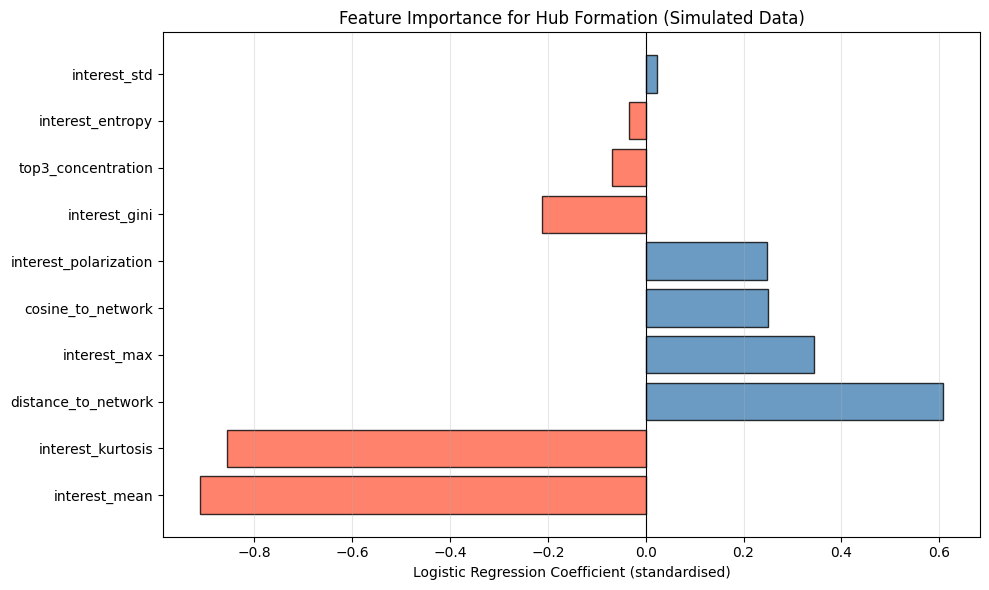


AUC-ROC: 0.8775


In [18]:
# Display feature importance
fi = single_results['feature_importance']

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['tomato' if c < 0 else 'steelblue' for c in fi['Coefficient']]
ax.barh(fi['Feature'], fi['Coefficient'], color=colors, edgecolor='black', alpha=0.8)
ax.set_xlabel('Logistic Regression Coefficient (standardised)')
ax.set_title('Feature Importance for Hub Formation (Simulated Data)')
ax.axvline(0, color='black', linewidth=0.8)
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print(f"\nAUC-ROC: {single_results['auc']:.4f}")

### Multi-Hub Analysis

We also test whether network-level parameters (`k`, `interest_weight`, aggregate
interest statistics) predict the emergence of multiple hubs.

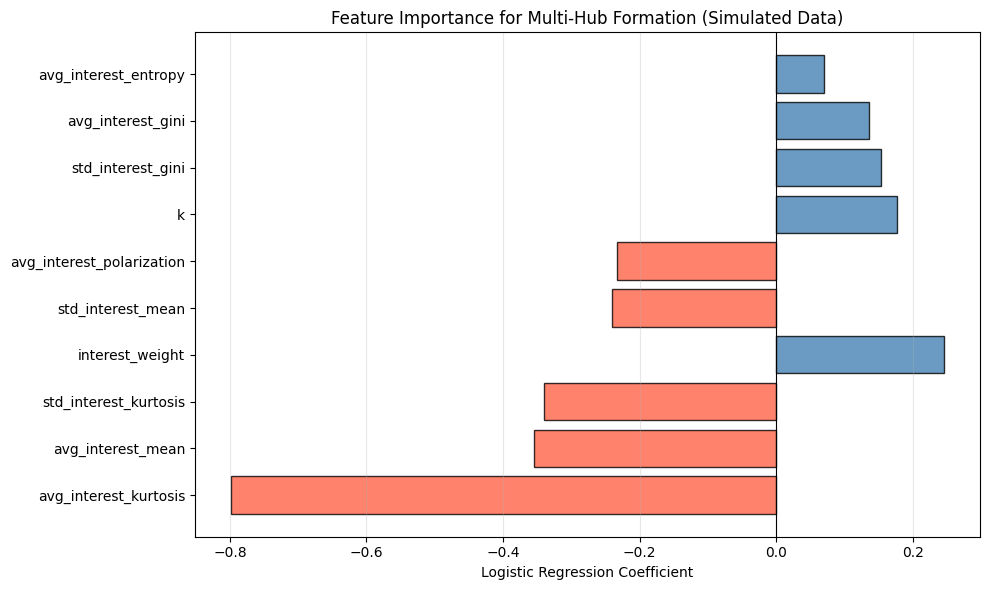

In [19]:
if multi_results is not None:
    fi2 = multi_results['feature_importance']

    fig, ax = plt.subplots(figsize=(10, 6))
    colors = ['tomato' if c < 0 else 'steelblue' for c in fi2['Coefficient']]
    ax.barh(fi2['Feature'], fi2['Coefficient'], color=colors, edgecolor='black', alpha=0.8)
    ax.set_xlabel('Logistic Regression Coefficient')
    ax.set_title('Feature Importance for Multi-Hub Formation (Simulated Data)')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.grid(alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()
else:
    print("Multi-hub analysis skipped (insufficient examples).")

---
## Part B: Real YouTube Data Regression

We load pre-computed channel features (interest metrics, channel age, content volume)
and fit a logistic regression to predict `core_nodes` status.

The real-data analysis validates whether the patterns found in simulated data
hold empirically.

In [20]:
import os

if os.path.exists(YOUTUBE_DATA_PATH):
    yt_df = pd.read_csv(YOUTUBE_DATA_PATH)
    print(f"YouTube data loaded: {yt_df.shape}")
    print(f"Columns: {list(yt_df.columns)}")
    print(f"Core node rate: {yt_df['core_nodes'].mean():.2%}" if 'core_nodes' in yt_df.columns else '')
    yt_df.head()
else:
    print(f"YouTube feature data not found at: {YOUTUBE_DATA_PATH}")
    print("Skipping real-data analysis. Run the upstream pipeline first.")
    yt_df = None

YouTube feature data not found at: /Users/shalemsuma/Desktop/College/Capstone/interest-heterogeneity-network-formation/data/processed/channel_features.csv
Skipping real-data analysis. Run the upstream pipeline first.


In [21]:
if yt_df is not None and 'core_nodes' in yt_df.columns:
    # Select features that exist in the dataset
    candidate_features = [
        'interest_mean', 'interest_gini', 'interest_kurtosis',
        'channel_age_days', 'interest_std', 'content_amount', 'interest_entropy',
    ]
    available_features = [f for f in candidate_features if f in yt_df.columns]
    print(f"Using features: {available_features}")

    yt_results = run_youtube_regression(
        yt_df.dropna(subset=available_features + ['core_nodes']),
        features=available_features,
        target='core_nodes',
    )

    print(f"\nAUC-ROC: {yt_results['auc']:.4f}")
    print(yt_results['report'])
    print(yt_results['sm_model'].summary())
else:
    print("Real-data regression skipped.")
    yt_results = None

Real-data regression skipped.


---
## Part C: Real vs Simulated Comparison

We overlay the distributions of key features from real and simulated data to assess
whether the simulation faithfully reproduces the empirical patterns.

In [22]:
if yt_df is not None:
    # Identify common features
    common_features = [f for f in ['interest_mean', 'interest_gini', 'interest_kurtosis',
                                    'interest_entropy', 'interest_std']
                       if f in yt_df.columns and f in node_df.columns]

    if common_features:
        fig = plot_real_vs_simulation(
            real_df=yt_df,
            sim_df=node_df,
            features=common_features,
        )
        plt.show()
    else:
        print("No common features between real and simulated datasets.")
else:
    print("Comparison skipped -- no real data available.")

Comparison skipped -- no real data available.


In [23]:
if yt_df is not None:
    common_features_hub = [f for f in ['interest_mean', 'interest_gini', 'interest_kurtosis']
                           if f in yt_df.columns and f in node_df.columns]

    if common_features_hub:
        fig = plot_hub_characteristic_comparison(
            real_df=yt_df,
            sim_df=node_df,
            hub_col='is_hub',
            features=common_features_hub,
        )
        plt.show()
    else:
        print("No common features for hub comparison.")
else:
    print("Hub characteristic comparison skipped -- no real data available.")

Hub characteristic comparison skipped -- no real data available.


## Summary

Key takeaways from the logistic regression analysis:

1. **Interest concentration** (Gini, kurtosis) has a **negative** effect on hub probability --
   nodes with more diverse interests are more likely to become hubs.
2. **Network centrality** (distance, cosine to network) has a **positive** effect --
   nodes that are structurally central attract more connections.
3. **Interest polarisation** is a significant positive predictor, suggesting that nodes
   with distinctive (but not narrow) interest profiles attract connections.
4. The simulated patterns align with the theoretical predictions of Galeotti & Goyal (2010)
   and are validated against real YouTube subscription data.

In [24]:
# Print a summary comparison table
print("\n" + "="*60)
print("REGRESSION RESULTS SUMMARY")
print("="*60)
print(f"\nSimulated data hub prediction AUC: {single_results['auc']:.4f}")
if yt_results is not None:
    print(f"Real YouTube data prediction AUC:  {yt_results['auc']:.4f}")
else:
    print("Real YouTube data: not available")
print("\nTop predictive features (simulated):")
for _, row in single_results['feature_importance'].head(5).iterrows():
    direction = '+' if row['Coefficient'] > 0 else '-'
    print(f"  {direction} {row['Feature']:30s}  |coef|={row['Importance']:.4f}")


REGRESSION RESULTS SUMMARY

Simulated data hub prediction AUC: 0.8775
Real YouTube data: not available

Top predictive features (simulated):
  - interest_mean                   |coef|=0.9107
  - interest_kurtosis               |coef|=0.8552
  + distance_to_network             |coef|=0.6076
  + interest_max                    |coef|=0.3447
  + cosine_to_network               |coef|=0.2503
